Library

In [ ]:
!pip -q install ultralytics

import hashlib
import shutil
import zipfile
from pathlib import Path

import torch
import yaml
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display
from google.colab import drive
from ultralytics import YOLO

print('GPU aktif:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('Nama GPU:', torch.cuda.get_device_name(0))

GPU aktif: True
Nama GPU: NVIDIA L4


Upload & Extract File Dataset.zip

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

file_zip_drive = Path('/content/drive/MyDrive/Dataset/dataset (2).zip                                                                           ')

if not file_zip_drive.exists():
    raise FileNotFoundError('File ZIP tidak ditemukan. Periksa path Google Drive.')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
folder_ekstrak = Path('dataset')

folder_ekstrak.mkdir(parents=True, exist_ok=True)
with zipfile.ZipFile(file_zip_drive, 'r') as file_zip:
    file_zip.extractall(folder_ekstrak)

print('Dataset diekstrak ke:', folder_ekstrak)

Dataset diekstrak ke: dataset


Memeriksa Dataset

In [ ]:
folder_dataset = None
for file_yaml in folder_ekstrak.rglob('data.yaml'):
    periksa_folder = file_yaml.parent
    if (periksa_folder / 'train' / 'images').is_dir() and \
       (periksa_folder / 'valid' / 'images').is_dir() and \
       (periksa_folder / 'test' / 'images').is_dir():
        folder_dataset = periksa_folder
        break

if folder_dataset is None:
    raise FileNotFoundError('Struktur dataset YOLO tidak ditemukan. Cek isi ZIP.')

with open(folder_dataset / 'data.yaml', 'r') as file:
    data_yaml = yaml.safe_load(file)

nama_kelas = data_yaml['names']
if isinstance(nama_kelas, dict):
    nama_kelas = [nama_kelas[k] for k in sorted(nama_kelas, key=lambda k: int(k))]

print('Jumlah kelas:', len(nama_kelas))
for nomor, nama in enumerate(nama_kelas):
    print(nomor, '-', nama)

ekstensi_gambar = ['.jpg', '.jpeg', '.png', '.webp', '.bmp']
jumlah_gambar = {}

for bagian in ['train', 'valid', 'test']:
    lokasi_gambar = folder_dataset / bagian / 'images'
    jumlah = 0
    for gambar in lokasi_gambar.iterdir():
        if gambar.is_file() and gambar.suffix.lower() in ekstensi_gambar:
            jumlah += 1
    jumlah_gambar[bagian] = jumlah
    print(bagian, ':', jumlah, 'gambar')

print('Total gambar:', sum(jumlah_gambar.values()))

Jumlah kelas: 14
0 - Fall-Detected
1 - Gloves
2 - Goggles
3 - Hardhat
4 - Ladder
5 - Mask
6 - NO-Gloves
7 - NO-Goggles
8 - NO-Hardhat
9 - NO-Mask
10 - NO-Safety Vest
11 - Person
12 - Safety Cone
13 - Safety Vest
train : 30765 gambar
valid : 8814 gambar
test : 4423 gambar
Total gambar: 44002


Cleaning

In [ ]:
from pathlib import Path
import shutil
import hashlib

folder_cleaning = Path('/content/dataset_cleaning')

if folder_cleaning.exists():
    shutil.rmtree(folder_cleaning)

jumlah_cleaning = {'train': 0, 'valid': 0, 'test': 0}
tanpa_label = 0
label_tidak_valid = 0
label_kosong = 0

for bagian in ['train', 'valid', 'test']:
    folder_gambar = folder_dataset / bagian / 'images'
    folder_label = folder_dataset / bagian / 'labels'

    if not folder_gambar.is_dir():
        raise FileNotFoundError(
            f'Folder gambar tidak ditemukan: {folder_gambar}'
        )

    if not folder_label.is_dir():
        raise FileNotFoundError(
            f'Folder label tidak ditemukan: {folder_label}'
        )

    tujuan_gambar = folder_cleaning / bagian / 'images'
    tujuan_label = folder_cleaning / bagian / 'labels'

    tujuan_gambar.mkdir(parents=True)
    tujuan_label.mkdir(parents=True)

    for gambar in sorted(folder_gambar.iterdir()):
        if not gambar.is_file():
            continue

        if gambar.suffix.lower() not in ekstensi_gambar:
            continue

        label = folder_label / (gambar.stem + '.txt')

        if not label.is_file():
            tanpa_label += 1
            continue

        isi_label = label.read_text(encoding='utf-8').splitlines()
        isi_label = [baris.strip() for baris in isi_label if baris.strip()]
        valid = True

        for baris in isi_label:
            kolom = baris.split()

            if len(kolom) != 5:
                valid = False
                break

            try:
                nilai = [float(angka) for angka in kolom]
                id_kelas = nilai[0]
                x, y, lebar, tinggi = nilai[1:]

                if not (
                    id_kelas.is_integer()
                    and 0 <= id_kelas < len(nama_kelas)
                    and 0 <= x <= 1
                    and 0 <= y <= 1
                    and 0 < lebar <= 1
                    and 0 < tinggi <= 1
                ):
                    valid = False
                    break

            except ValueError:
                valid = False
                break

        if not valid:
            label_tidak_valid += 1
            continue

        if len(isi_label) == 0:
            label_kosong += 1

        shutil.copy2(gambar, tujuan_gambar / gambar.name)

        (tujuan_label / label.name).write_text(
            '\n'.join(isi_label) + ('\n' if isi_label else ''),
            encoding='utf-8'
        )

        jumlah_cleaning[bagian] += 1

print('HASIL CLEANING')
print('Jumlah setelah cleaning:', jumlah_cleaning)
print('Gambar tanpa label:', tanpa_label)
print('Label tidak valid:', label_tidak_valid)
print('Label kosong yang dipertahankan:', label_kosong)

HASIL CLEANING
Jumlah setelah cleaning: {'train': 30765, 'valid': 8814, 'test': 4423}
Gambar tanpa label: 0
Label tidak valid: 0
Label kosong yang dipertahankan: 1190


Check Duplicate

In [ ]:
folder_bersih = Path('/content/dataset_bersih')

if folder_bersih.exists():
    shutil.rmtree(folder_bersih)

hash_terpakai = {}
jumlah_bersih = {'train': 0, 'valid': 0, 'test': 0}
gambar_duplikat = 0
duplikat_label_berbeda = 0
label_kosong_bersih = 0

for bagian in ['train', 'valid', 'test']:
    folder_gambar = folder_cleaning / bagian / 'images'
    folder_label = folder_cleaning / bagian / 'labels'

    tujuan_gambar = folder_bersih / bagian / 'images'
    tujuan_label = folder_bersih / bagian / 'labels'

    tujuan_gambar.mkdir(parents=True)
    tujuan_label.mkdir(parents=True)

    for gambar in sorted(folder_gambar.iterdir()):
        if not gambar.is_file():
            continue

        if gambar.suffix.lower() not in ekstensi_gambar:
            continue

        label = folder_label / (gambar.stem + '.txt')

        isi_label = label.read_text(encoding='utf-8').splitlines()
        isi_label = [baris.strip() for baris in isi_label if baris.strip()]

        kode_hash = hashlib.sha256(gambar.read_bytes()).hexdigest()
        isi_anotasi = tuple(sorted(isi_label))

        if kode_hash in hash_terpakai:
            gambar_duplikat += 1

            if isi_anotasi != hash_terpakai[kode_hash]:
                duplikat_label_berbeda += 1

            continue

        hash_terpakai[kode_hash] = isi_anotasi

        gambar_baru = tujuan_gambar / (
            kode_hash + gambar.suffix.lower()
        )
        label_baru = tujuan_label / (kode_hash + '.txt')

        shutil.copy2(gambar, gambar_baru)

        label_baru.write_text(
            '\n'.join(isi_label) + ('\n' if isi_label else ''),
            encoding='utf-8'
        )

        jumlah_bersih[bagian] += 1

        if len(isi_label) == 0:
            label_kosong_bersih += 1

print('HASIL DEDUPLIKASI')
print('Jumlah sebelum deduplikasi:', jumlah_cleaning)
print('Jumlah setelah deduplikasi:', jumlah_bersih)
print('Total gambar akhir:', sum(jumlah_bersih.values()))
print('Gambar duplikat yang disisihkan:', gambar_duplikat)
print('Duplikat dengan anotasi berbeda:', duplikat_label_berbeda)
print('Label kosong pada hasil akhir:', label_kosong_bersih)

HASIL DEDUPLIKASI
Jumlah sebelum deduplikasi: {'train': 30765, 'valid': 8814, 'test': 4423}
Jumlah setelah deduplikasi: {'train': 29014, 'valid': 7809, 'test': 3851}
Total gambar akhir: 40674
Gambar duplikat yang disisihkan: 3328
Duplikat dengan anotasi berbeda: 3266
Label kosong pada hasil akhir: 1120


Split

In [ ]:
total_gambar = sum(jumlah_bersih.values())
if total_gambar == 0:
    raise ValueError('Tidak ada gambar yang tersisa. Periksa hasil cleaning.')

for bagian in ['train', 'valid', 'test']:
    if jumlah_bersih[bagian] == 0:
        raise ValueError(f'Data {bagian} kosong. Periksa dataset.')
    persen = jumlah_bersih[bagian] / total_gambar * 100
    print(f'{bagian}: {jumlah_bersih[bagian]} gambar ({persen:.2f}%)')

print('Total gambar bersih:', total_gambar)

konfigurasi_yolo = {
    'path': str(folder_bersih),
    'train': 'train/images',
    'val': 'valid/images',
    'test': 'test/images',
    'names': nama_kelas
}

file_yaml_bersih = folder_bersih / 'data.yaml'
with open(file_yaml_bersih, 'w') as file:
    yaml.safe_dump(konfigurasi_yolo, file, allow_unicode=True, sort_keys=False)

print('File konfigurasi:', file_yaml_bersih)

train: 29014 gambar (71.33%)
valid: 7809 gambar (19.20%)
test: 3851 gambar (9.47%)
Total gambar bersih: 40674
File konfigurasi: /content/dataset_bersih/data.yaml


Modeling

In [ ]:
if not torch.cuda.is_available():
    raise RuntimeError('GPU belum aktif.')

nama_model = 'yolo11n.pt'
epoch = 30
batch_size = 8
ukuran_gambar = 640

model = YOLO(nama_model)
print('Model:', nama_model)
print('Epoch:', epoch)
print('Batch size:', batch_size)
print('Ukuran input:', ukuran_gambar)

Model: yolo11n.pt
Epoch: 30
Batch size: 8
Ukuran input: 640


Training

In [ ]:
hasil_training = model.train(
    amp=True,
    data=str(file_yaml_bersih),
    epochs=epoch,
    batch=batch_size,
    imgsz=ukuran_gambar,
    device=0,
    mosaic=0.0,
    workers=0,
    plots=True,
    project='/content/PPE_Runs',
    name='training_yolo11',
    exist_ok=True
)

folder_training = Path(model.trainer.save_dir)
file_model_terbaik = folder_training / 'weights' / 'best.pt'
print('File model terbaik:', file_model_terbaik)

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset_bersih/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=0.0, multi_scale=0.0, name=training_yolo11, nbs=64, nms=None, opset=None, optimize

Validasi perkembangan Matriks

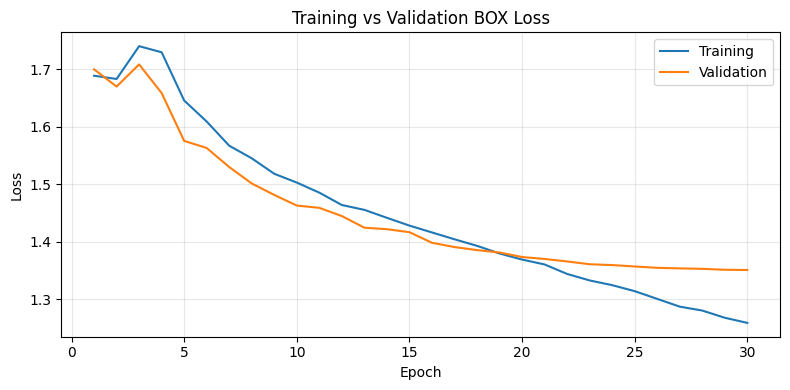

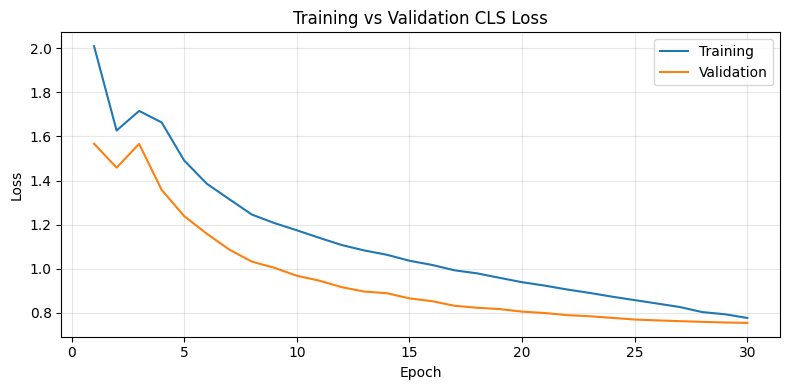

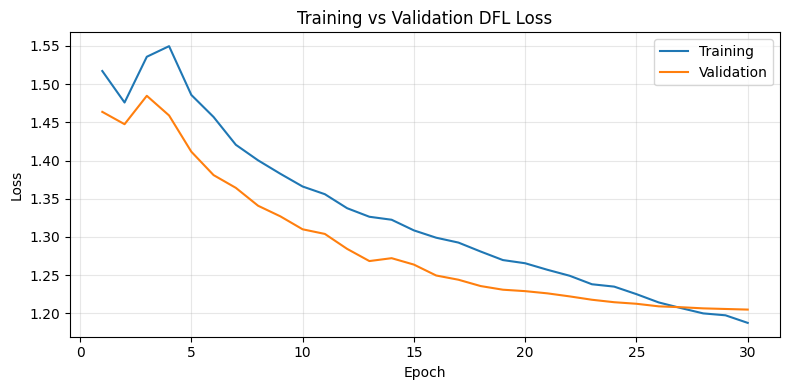

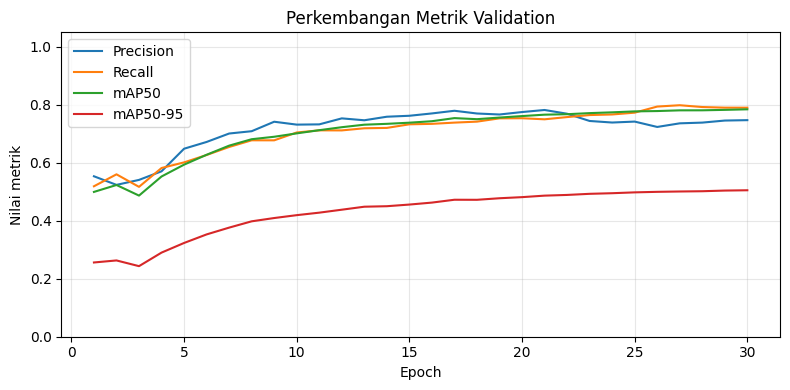

In [ ]:
file_riwayat = folder_training / 'results.csv'
riwayat = pd.read_csv(file_riwayat)
riwayat.columns = riwayat.columns.str.strip()

for jenis in ['box', 'cls', 'dfl']:
    kolom_train = 'train/' + jenis + '_loss'
    kolom_valid = 'val/' + jenis + '_loss'

    if kolom_train not in riwayat.columns or kolom_valid not in riwayat.columns:
        print('Kolom tidak ditemukan:', jenis)
        continue

    plt.figure(figsize=(8, 4))
    plt.plot(riwayat['epoch'], riwayat[kolom_train], label='Training')
    plt.plot(riwayat['epoch'], riwayat[kolom_valid], label='Validation')
    plt.title('Training vs Validation ' + jenis.upper() + ' Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(folder_training / ('grafik_loss_' + jenis + '.png'))
    plt.show()

metrik_kolom = {
    'metrics/precision(B)': 'Precision',
    'metrics/recall(B)': 'Recall',
    'metrics/mAP50(B)': 'mAP50',
    'metrics/mAP50-95(B)': 'mAP50-95'
}

plt.figure(figsize=(8, 4))
for nama_kolom, nama_metrik in metrik_kolom.items():
    if nama_kolom in riwayat.columns:
        plt.plot(riwayat['epoch'], riwayat[nama_kolom], label=nama_metrik)

plt.title('Perkembangan Metrik Validation')
plt.xlabel('Epoch')
plt.ylabel('Nilai metrik')
plt.ylim(0, 1.05)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(folder_training / 'grafik_metrik.png')
plt.show()

Evaluasi

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
YOLO11n summary (fused): 101 layers, 2,600,210 parameters, 0 gradients, 6.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1334.7±448.8 MB/s, size: 51.4 KB)
val: Scanning /content/dataset_bersih/test/labels... 3851 images, 117 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 3851/3851 1.5Kit/s 2.6s
val: New cache created: /content/dataset_bersih/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 482/482 22.4it/s 21.5s
                   all       3851       9957      0.734       0.79      0.784      0.502
         Fall-Detected        450        450      0.727      0.787      0.804      0.501
                Gloves        195        425      0.823      0.932      0.943       0.49
               Goggles        356        386       0.85      0.982      0.968      0.579
               Hardhat       1477       4127      0.883    

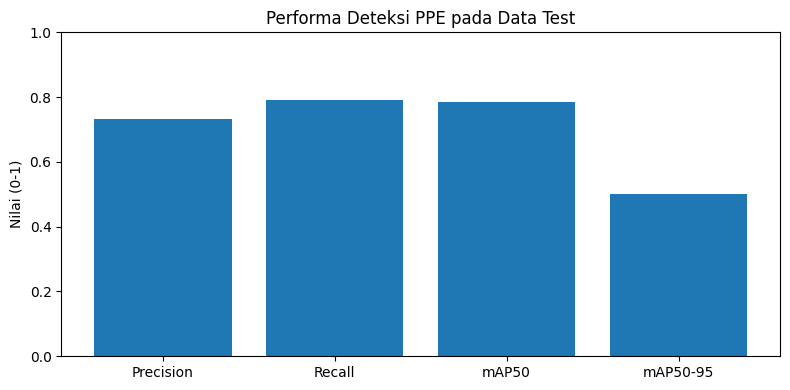

In [ ]:
model_terbaik = YOLO(str(file_model_terbaik))

hasil_evaluasi = model_terbaik.val(
    data=str(file_yaml_bersih),
    split='test',
    device=0,
    batch=batch_size,
    plots=True,
    project='/content/PPE_Runs',
    name='evaluasi_test',
    exist_ok=True
)

folder_evaluasi = Path('/content/PPE_Runs/evaluasi_test')
precision = float(hasil_evaluasi.box.mp)
recall = float(hasil_evaluasi.box.mr)
map50 = float(hasil_evaluasi.box.map50)
map5095 = float(hasil_evaluasi.box.map)

print('Precision:', round(precision, 4))
print('Recall:', round(recall, 4))
print('mAP50:', round(map50, 4))
print('mAP50-95:', round(map5095, 4))

plt.figure(figsize=(8, 4))
plt.bar(['Precision', 'Recall', 'mAP50', 'mAP50-95'],
        [precision, recall, map50, map5095])
plt.title('Performa Deteksi PPE pada Data Test')
plt.ylabel('Nilai (0-1)')
plt.ylim(0, 1)
plt.tight_layout()
plt.savefig(folder_evaluasi / 'grafik_performa_test.png')
plt.show()

In [ ]:
if 'hasil_evaluasi' not in globals():
    print('Jalankan sel Evaluasi di atas terlebih dahulu.')
else:
    metrik = hasil_evaluasi.box
    precision_persen = float(metrik.mp) * 100
    recall_persen = float(metrik.mr) * 100
    map50_persen = float(metrik.map50) * 100
    map5095_persen = float(metrik.map) * 100

    if len(metrik.f1) > 0:
        f1_persen = float(metrik.f1.mean()) * 100
        print(f'F1 rata-rata kelas: {f1_persen:.2f}%')
    else:
        print('F1 belum tersedia. Periksa label pada data test.')

    print(f'Precision         : {precision_persen:.2f}%')
    print(f'Recall            : {recall_persen:.2f}%')
    print(f'mAP50             : {map50_persen:.2f}%')
    print(f'mAP50-95          : {map5095_persen:.2f}%')
    print('mAP50: evaluasi pada IoU 0.50.')
    print('mAP50-95: rata-rata pada IoU 0.50 sampai 0.95.')
    print('P, R, dan F1 mengikuti titik confidence pilihan evaluator.')
    print('Laporkan nama metriknya; jangan mengganti mAP menjadi accuracy.')

F1 rata-rata kelas: 75.28%
Precision         : 73.37%
Recall            : 78.99%
mAP50             : 78.35%
mAP50-95          : 50.24%
mAP50: evaluasi pada IoU 0.50.
mAP50-95: rata-rata pada IoU 0.50 sampai 0.95.
P, R, dan F1 mengikuti titik confidence pilihan evaluator.
Laporkan nama metriknya; jangan mengganti mAP menjadi accuracy.


Confusion Matrix

confusion_matrix.png


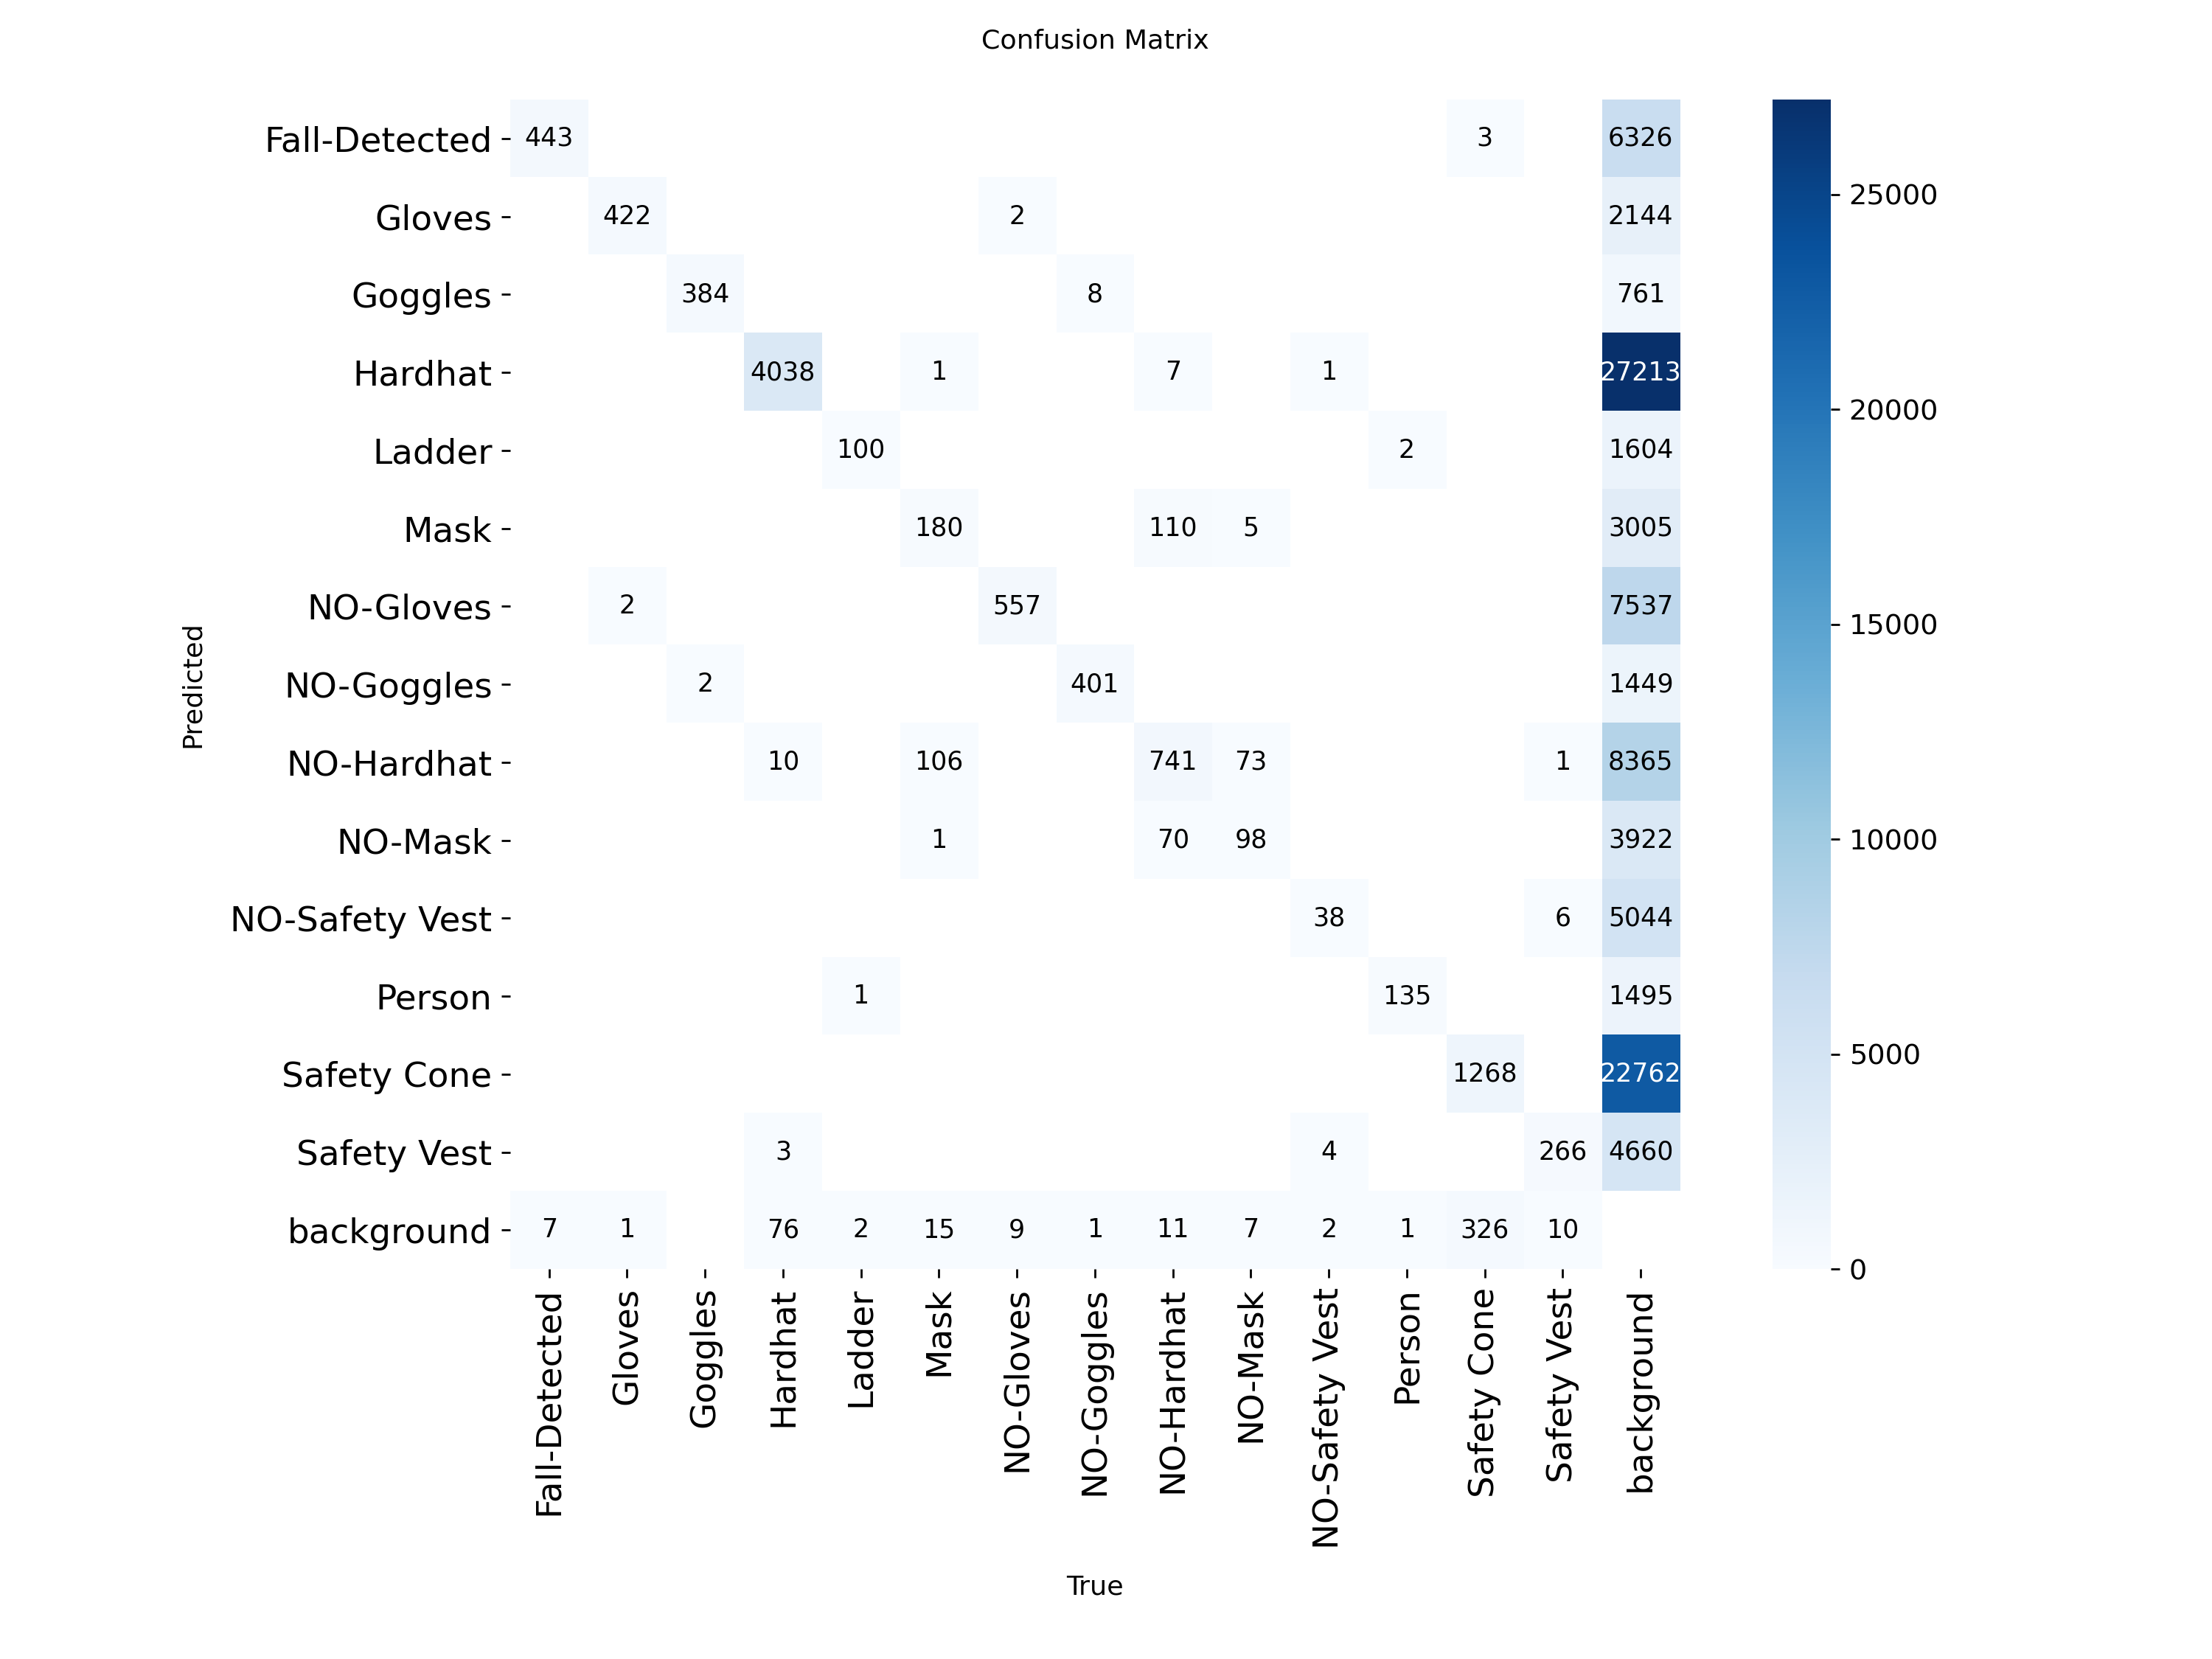

confusion_matrix_normalized.png


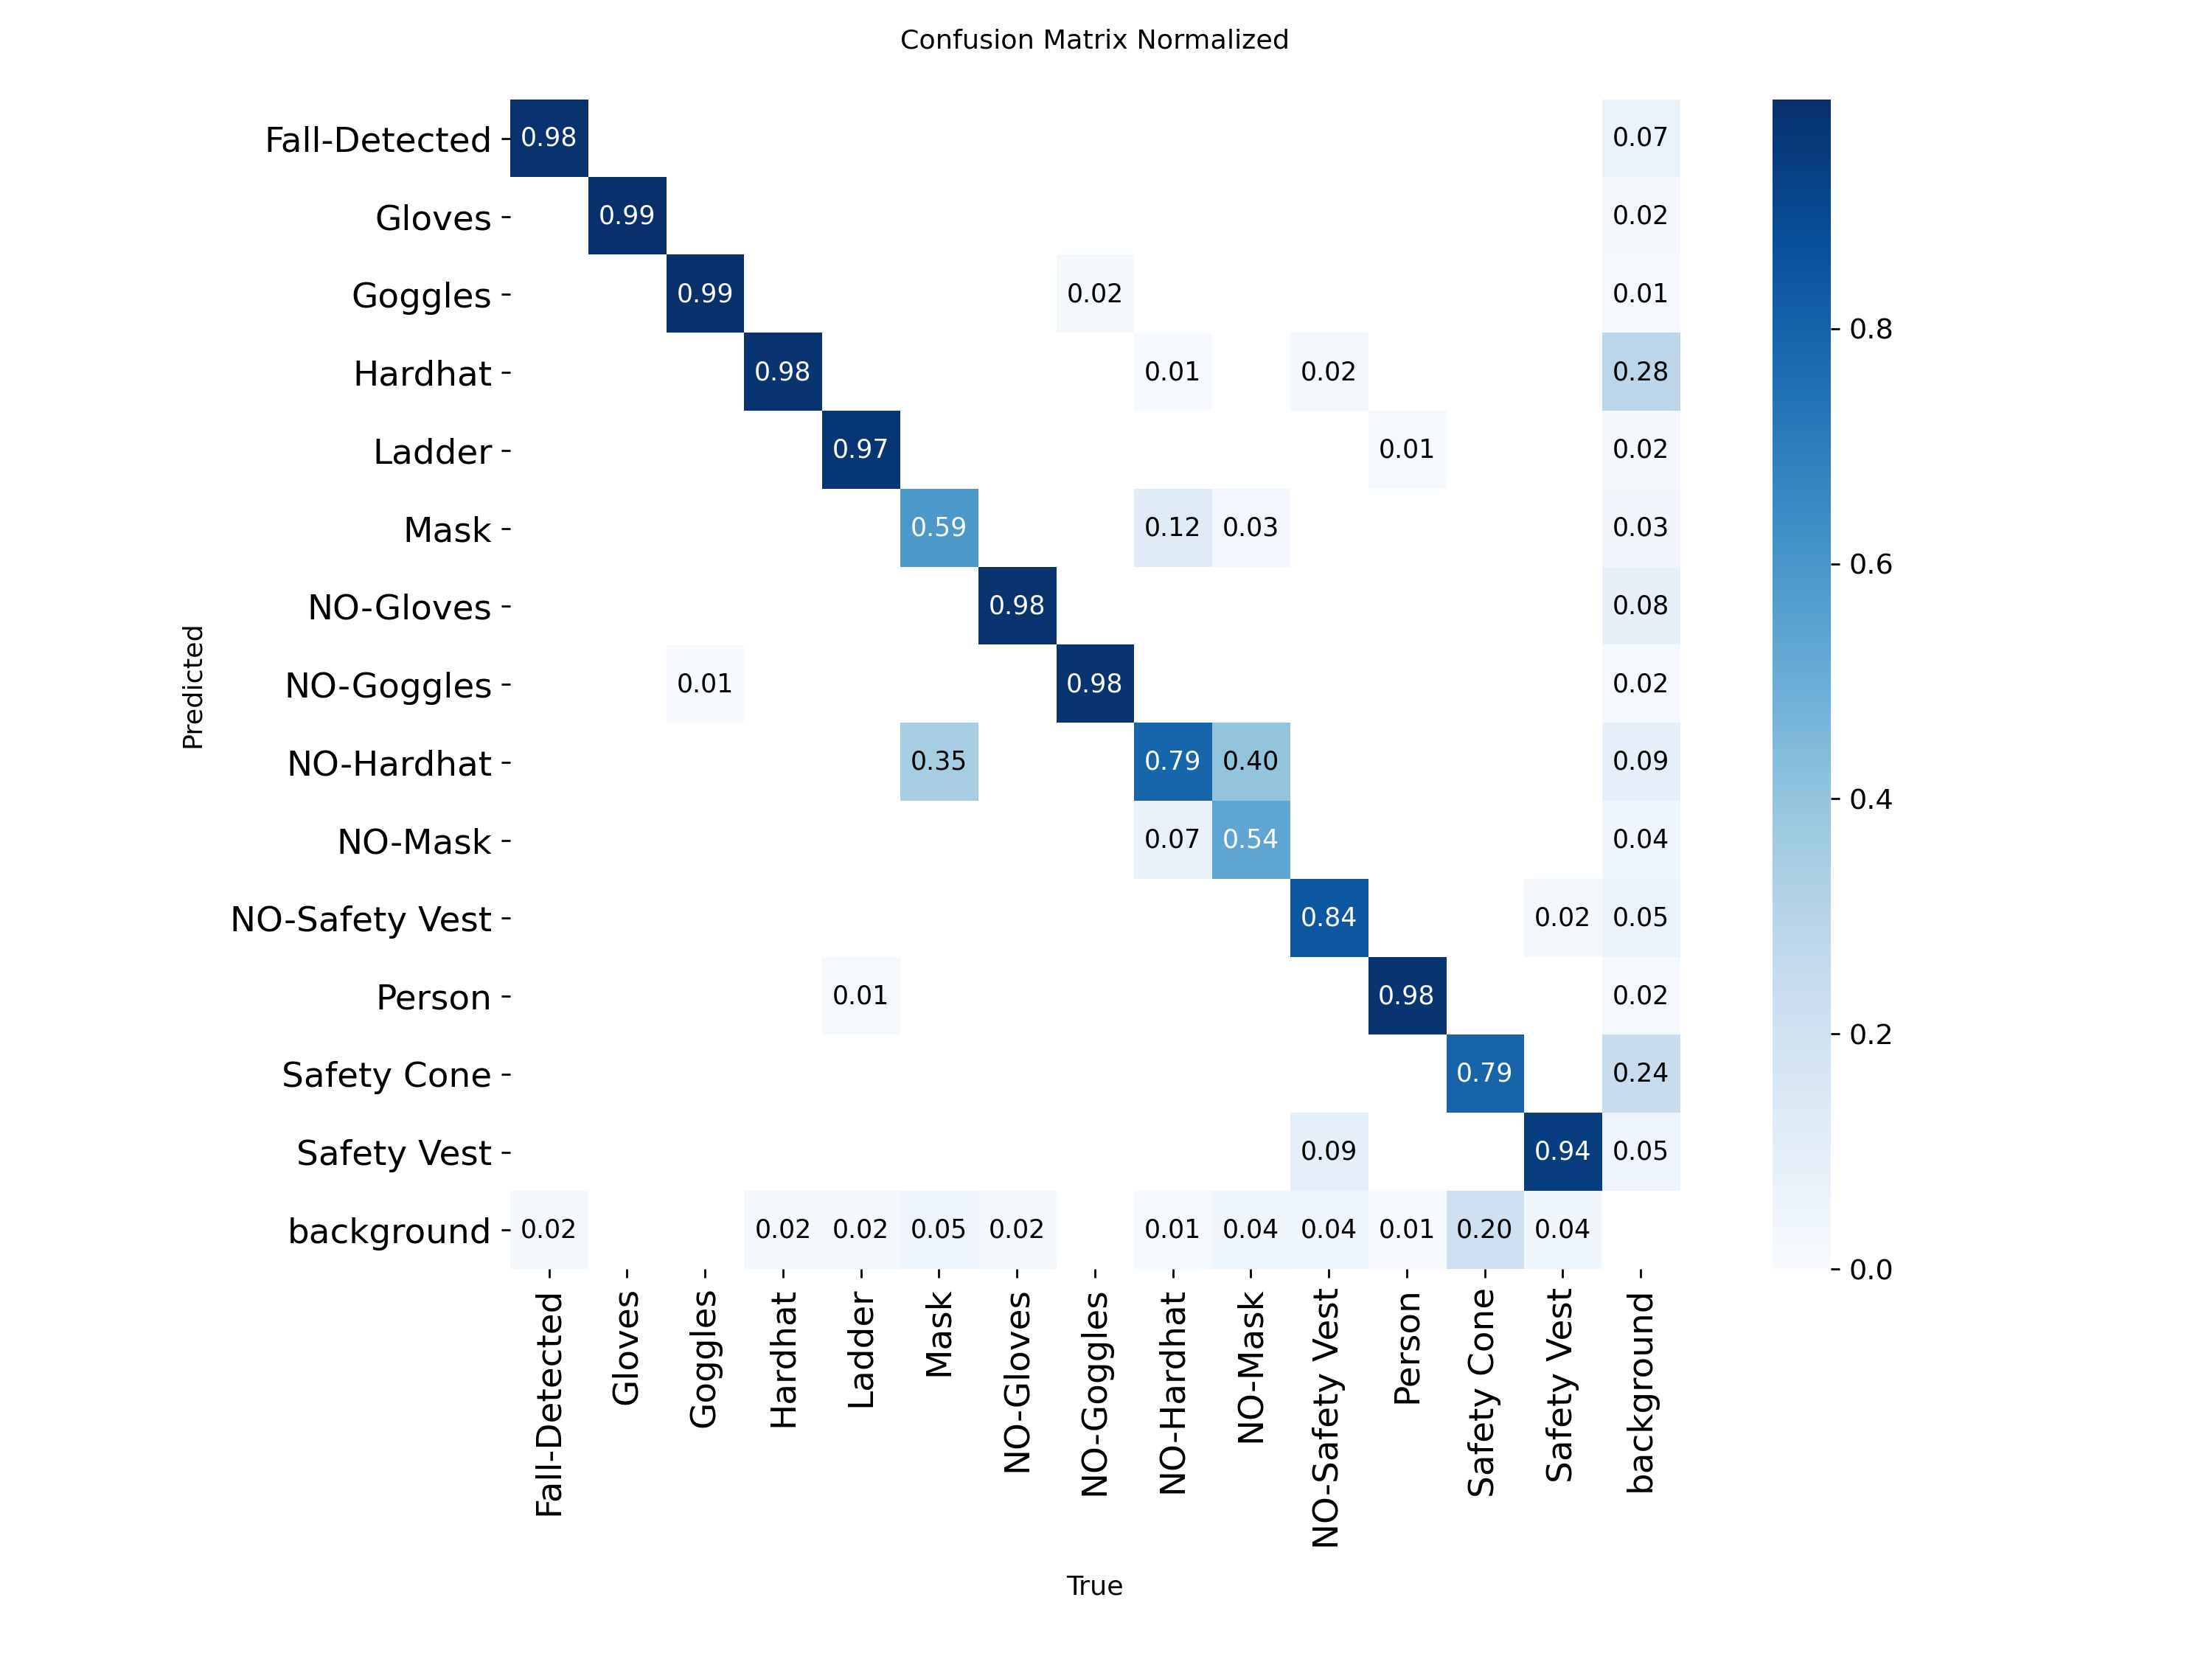

In [ ]:
for nama_file in ['confusion_matrix.png', 'confusion_matrix_normalized.png']:
    lokasi_gambar = folder_evaluasi / nama_file
    if lokasi_gambar.exists():
        print(nama_file)
        display(Image.open(lokasi_gambar))
    else:
        print('Belum ditemukan:', lokasi_gambar)

hasil per kelas

In [ ]:
hasil_per_kelas = []
for urutan, nomor_kelas in enumerate(hasil_evaluasi.box.ap_class_index):
    p, r, ap50, ap5095 = hasil_evaluasi.box.class_result(urutan)
    hasil_per_kelas.append({
        'Kelas': nama_kelas[int(nomor_kelas)],
        'Precision': round(float(p), 3),
        'Recall': round(float(r), 3),
        'mAP50': round(float(ap50), 3),
        'mAP50-95': round(float(ap5095), 3)
    })

if hasil_per_kelas:
    tabel_kelas = pd.DataFrame(hasil_per_kelas)
    display(tabel_kelas)
    tabel_kelas.to_csv(folder_evaluasi / 'hasil_per_kelas.csv', index=False)
else:
    print('Tidak ada kelas yang dapat dihitung. Periksa data test.')

,Kelas,Precision,Recall,mAP50,mAP50-95
0,Fall-Detected,0.727,0.787,0.804,0.501
1,Gloves,0.823,0.932,0.943,0.490
2,Goggles,0.850,0.982,0.968,0.579
3,Hardhat,0.883,0.899,0.930,0.541
4,Ladder,0.850,0.971,0.970,0.826
5,Mask,0.504,0.683,0.504,0.322
6,NO-Gloves,0.790,0.863,0.882,0.440
7,NO-Goggles,0.844,0.920,0.948,0.562
8,NO-Hardhat,0.661,0.873,0.829,0.549
9,NO-Mask,0.495,0.732,0.584,0.361


Testing


image 1/1 /content/dataset_bersih/test/images/40187a0a6ae168f5ed6c188694c1e6cf242727eac19e786cda44ac40d72516cb.jpg: 640x640 1 Goggles, 9.0ms
Speed: 1.1ms preprocess, 9.0ms inference, 1.5ms postprocess per image at shape (1, 3, 640, 640)
Gambar yang diuji: 40187a0a6ae168f5ed6c188694c1e6cf242727eac19e786cda44ac40d72516cb.jpg


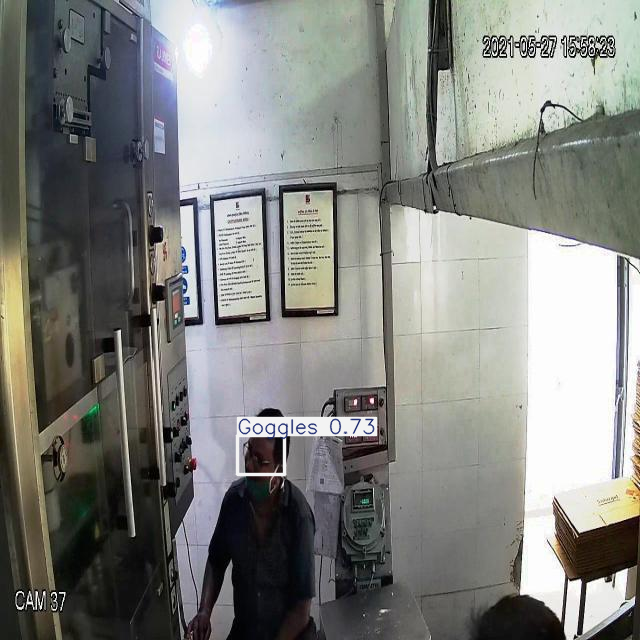

In [ ]:
folder_test = folder_bersih / 'test' / 'images'
gambar_uji = None
for gambar in folder_test.iterdir():
    if gambar.suffix.lower() in ekstensi_gambar:
        gambar_uji = gambar
        break

if gambar_uji is None:
    raise FileNotFoundError('Gambar test tidak ditemukan.')

prediksi = model_terbaik.predict(source=str(gambar_uji), conf=0.05)
print('Gambar yang diuji:', gambar_uji.name)
display(Image.fromarray(prediksi[0].plot()[..., ::-1]))

Testing menggunakan Gambar External/Baru

Saving istockphoto-2117759132-612x612.jpg to istockphoto-2117759132-612x612.jpg
Saving istockphoto-2187596750-612x612.jpg to istockphoto-2187596750-612x612.jpg
Saving istockphoto-1042342584-612x612.jpg to istockphoto-1042342584-612x612.jpg
Saving istockphoto-1332162803-612x612.jpg to istockphoto-1332162803-612x612.jpg
Saving istockphoto-1487278371-612x612.jpg to istockphoto-1487278371-612x612.jpg

0: 864x1280 6 Hardhats, 4 Safety Vests, 10.9ms
Speed: 4.2ms preprocess, 10.9ms inference, 1.7ms postprocess per image at shape (1, 3, 864, 1280)
Results saved to /content/PPE_Runs/testing_local
Nama gambar: istockphoto-2117759132-612x612.jpg


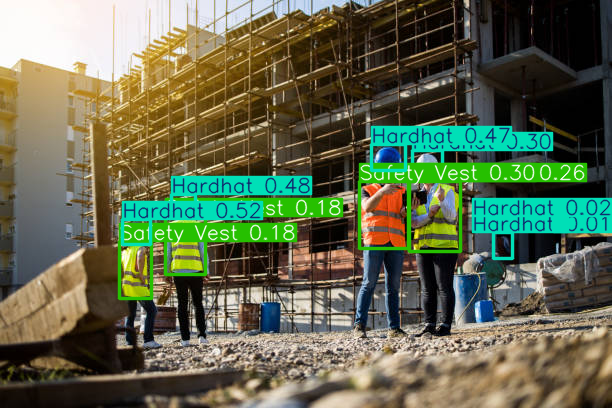


0: 864x1280 2 Hardhats, 2 NO-Hardhats, 1 NO-Safety Vest, 5 Safety Vests, 10.1ms
Speed: 3.6ms preprocess, 10.1ms inference, 1.5ms postprocess per image at shape (1, 3, 864, 1280)
Results saved to /content/PPE_Runs/testing_local
Nama gambar: istockphoto-2187596750-612x612.jpg


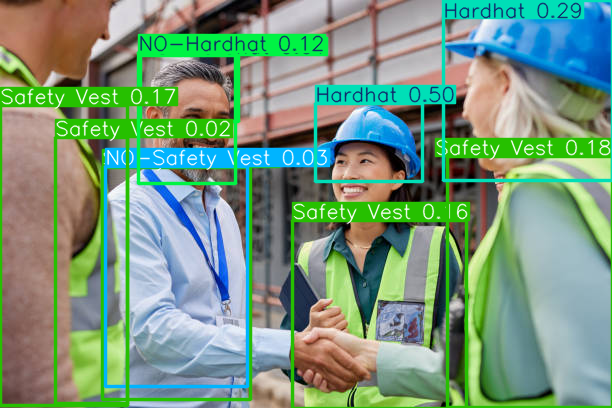


0: 864x1280 3 Hardhats, 2 NO-Safety Vests, 3 Safety Vests, 10.4ms
Speed: 3.6ms preprocess, 10.4ms inference, 1.5ms postprocess per image at shape (1, 3, 864, 1280)
Results saved to /content/PPE_Runs/testing_local
Nama gambar: istockphoto-1042342584-612x612.jpg


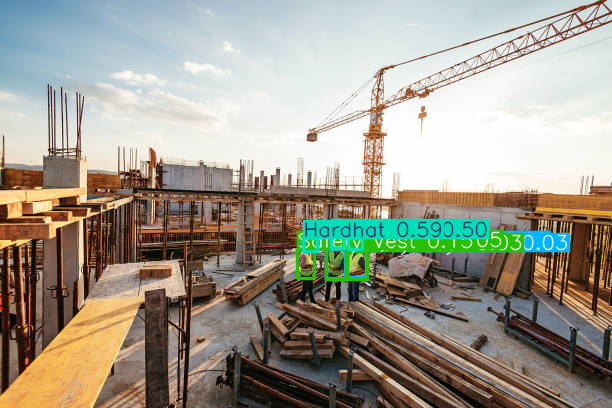


0: 864x1280 2 Fall-Detecteds, 4 Hardhats, 3 Safety Vests, 10.1ms
Speed: 3.6ms preprocess, 10.1ms inference, 1.8ms postprocess per image at shape (1, 3, 864, 1280)
Results saved to /content/PPE_Runs/testing_local
Nama gambar: istockphoto-1332162803-612x612.jpg


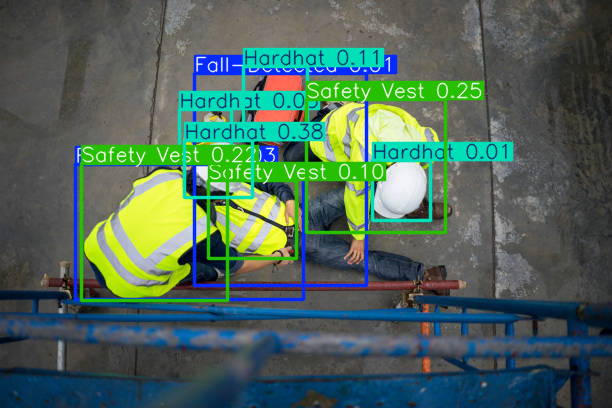


0: 864x1280 5 Hardhats, 4 Safety Vests, 10.1ms
Speed: 3.7ms preprocess, 10.1ms inference, 1.5ms postprocess per image at shape (1, 3, 864, 1280)
Results saved to /content/PPE_Runs/testing_local
Nama gambar: istockphoto-1487278371-612x612.jpg


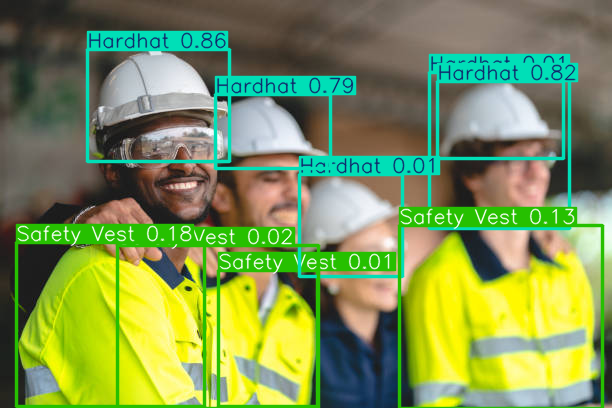

In [ ]:
from google.colab import files
from PIL import Image
from IPython.display import display

# Membuka tombol untuk memilih gambar dari komputer.
gambar_upload = files.upload()

# Melakukan prediksi untuk setiap gambar yang diunggah.
for nama_file, isi_file in gambar_upload.items():
    gambar = Image.open(nama_file).convert('RGB')

    hasil_prediksi = model_terbaik.predict(
        source=gambar,
        imgsz=1280,
        conf=0.01,
        classes=None,
        agnostic_nms=False,
        max_det=100,
        save=True,
        project='/content/PPE_Runs',
        name='testing_local',
        exist_ok=True
    )

    print('Nama gambar:', nama_file)

    # Mengubah warna BGR menjadi RGB agar tampil dengan benar.
    gambar_hasil = hasil_prediksi[0].plot()
    display(Image.fromarray(gambar_hasil[..., ::-1]))

### Backup Seluruh Isi `/content` ke Google Drive

Sel berikut akan mengompres seluruh file dan folder yang berada di `/content` (tidak termasuk folder `/content/drive` untuk menghindari duplikasi tak terbatas) menjadi satu file ZIP, kemudian menyimpannya ke Google Drive Anda.

In [ ]:
import os
import zipfile
from pathlib import Path

def backup_seluruh_content():
    path_drive_tujuan = Path('/content/drive/MyDrive/Dataset')
    path_drive_tujuan.mkdir(parents=True, exist_ok=True)

    file_zip_backup = path_drive_tujuan / 'Backup_All_Content.zip'
    content_dir = Path('/content')

    print('Memulai proses backup seluruh isi /content...')

    with zipfile.ZipFile(file_zip_backup, 'w', zipfile.ZIP_DEFLATED) as zip_file:
        for root, dirs, files in os.walk(content_dir):
            # Abaikan folder drive untuk mencegah loop rekursif
            if 'drive' in dirs:
                dirs.remove('drive')
            if '.config' in dirs:
                dirs.remove('.config') # Opsional: abaikan file konfigurasi internal Colab

            for file in files:
                filepath = Path(root) / file
                # Abaikan file zip backup itu sendiri jika disimpan di lokasi yang sama
                if filepath == file_zip_backup:
                    continue

                relatif_path = filepath.relative_to(content_dir)
                zip_file.write(filepath, relatif_path)

    print(f'Backup selesai! Seluruh isi /content berhasil disimpan ke: {file_zip_backup}')

backup_seluruh_content()

Memulai proses backup seluruh isi /content...
Backup selesai! Seluruh isi /content berhasil disimpan ke: /content/drive/MyDrive/Dataset/Backup_All_Content.zip
